## Imports CTGAN

- CTGAN: Generative Model
- Table evaluator: Allows comparing real data vs. synthesized data


In [ ]:
# Import libraries
import torch
import pandas as pd
import seaborn as sns
import torch.nn as nn

In [ ]:
# Install CTGAN
!pip install ctgan

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.8/74.8 kB 2.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 35.0 MB/s eta 0:00:00


In [ ]:
!pip install table_evaluator

In [ ]:
#import pandas as pd
from ctgan import CTGAN
from table_evaluator import TableEvaluator

### Remove unnecessary columns and encode all data

Next, we read the data into a dataframe and drop the unnecessary columns.

In [ ]:
file_name = 'https://raw.githubusercontent.com/jamaltoutouh/gan-tabular-data-example/main/patients.csv'
data = pd.read_csv(file_name)
data

,Id,BIRTHDATE,DEATHDATE,SSN,DRIVERS,PASSPORT,PREFIX,FIRST,LAST,SUFFIX,...,BIRTHPLACE,ADDRESS,CITY,STATE,COUNTY,ZIP,LAT,LON,HEALTHCARE_EXPENSES,HEALTHCARE_COVERAGE
0,1d604da9-9a81-4ba9-80c2-de3375d59b40,1989-05-25,NaN,999-76-6866,S99984236,X19277260X,Mr.,José Eduardo181,Gómez206,NaN,...,Marigot Saint Andrew Parish DM,427 Balistreri Way Unit 19,Chicopee,Massachusetts,Hampden County,1013.0,42.228354,-72.562951,271227.08,1334.88
1,034e9e3b-2def-4559-bb2a-7850888ae060,1983-11-14,NaN,999-73-5361,S99962402,X88275464X,Mr.,Milo271,Feil794,NaN,...,Danvers Massachusetts US,422 Farrell Path Unit 69,Somerville,Massachusetts,Middlesex County,2143.0,42.360697,-71.126531,793946.01,3204.49
2,10339b10-3cd1-4ac3-ac13-ec26728cb592,1992-06-02,NaN,999-27-3385,S99972682,X73754411X,Mr.,Jayson808,Fadel536,NaN,...,Springfield Massachusetts US,1056 Harris Lane Suite 70,Chicopee,Massachusetts,Hampden County,1020.0,42.181642,-72.608842,574111.90,2606.40
3,8d4c4326-e9de-4f45-9a4c-f8c36bff89ae,1978-05-27,NaN,999-85-4926,S99974448,X40915583X,Mrs.,Mariana775,Rutherford999,NaN,...,Yarmouth Massachusetts US,999 Kuhn Forge,Lowell,Massachusetts,Middlesex County,1851.0,42.636143,-71.343255,935630.30,8756.19
4,f5dcd418-09fe-4a2f-baa0-3da800bd8c3a,1996-10-18,NaN,999-60-7372,S99915787,X86772962X,Mr.,Gregorio366,Auer97,NaN,...,Patras Achaea GR,1050 Lindgren Extension Apt 38,Boston,Massachusetts,Suffolk County,2135.0,42.352434,-71.028610,598763.07,3772.20
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1166,023a7d29-32b3-4db5-89c8-b88bd7582ec0,1922-02-14,NaN,999-60-9291,S99949872,X45944669X,Mrs.,Conchita9,Peres371,NaN,...,Juarez Chihuahua MX,365 Gorczany Crossing Apt 64,Cambridge,Massachusetts,Middlesex County,2141.0,42.413390,-71.102083,1622314.87,32086.31
1167,1fc8dafd-90e5-44d6-9179-81156c0ea083,1977-08-08,NaN,999-29-3501,S99999143,X43299813X,Mr.,Laverne101,Hane680,NaN,...,Upton Massachusetts US,177 Volkman Heights Suite 94,Beverly,Massachusetts,Essex County,1915.0,42.573337,-70.883400,979724.25,3130.52
1168,6d048a56-edb8-4f29-891d-7a84d75a8e78,1914-09-05,2006-05-26,999-60-2184,S99940416,X26292359X,Ms.,Kimber624,Volkman526,NaN,...,Fall River Massachusetts US,583 Price Rue,Norwood,Massachusetts,Norfolk County,NaN,42.211364,-71.213621,1560540.35,52391.24
1169,fca3178e-fb68-41c3-8598-702d3ca68b96,1914-09-05,1990-03-17,999-48-3257,S99949673,X25242364X,Mrs.,Shira43,Bruen238,NaN,...,Springfield Massachusetts US,537 Boehm Course,Norwood,Massachusetts,Norfolk County,2062.0,42.167146,-71.235461,1375833.47,13157.00


In [ ]:
data.columns

Index(['Id', 'BIRTHDATE', 'DEATHDATE', 'SSN', 'DRIVERS', 'PASSPORT', 'PREFIX',
       'FIRST', 'LAST', 'SUFFIX', 'MAIDEN', 'MARITAL', 'RACE', 'ETHNICITY',
       'GENDER', 'BIRTHPLACE', 'ADDRESS', 'CITY', 'STATE', 'COUNTY', 'ZIP',
       'LAT', 'LON', 'HEALTHCARE_EXPENSES', 'HEALTHCARE_COVERAGE'],
      dtype='object')

In [ ]:
data.drop(['Id', 'BIRTHDATE', 'DEATHDATE', 'SSN', 'DRIVERS', 'PASSPORT', 'PREFIX',
       'FIRST', 'ADDRESS', 'LAST', 'SUFFIX', 'MAIDEN','LAT', 'LON',], axis=1, inplace=True)
print(data.columns)

Index(['MARITAL', 'RACE', 'ETHNICITY', 'GENDER', 'BIRTHPLACE', 'CITY', 'STATE',
       'COUNTY', 'ZIP', 'HEALTHCARE_EXPENSES', 'HEALTHCARE_COVERAGE'],
      dtype='object')


Next, we define a list with column names for categorical variables. This list will be passed to the model so that the model can decide how to process these fields.

In [ ]:
categorical_features = ['MARITAL', 'RACE', 'ETHNICITY', 'GENDER', 'BIRTHPLACE', 'CITY', 'STATE', 'COUNTY', 'ZIP']

## Training the model

Next, we simply define an instance of `CTGAN` and call the `fit` method with the dataframe and the list of categorical variables.

We train the model for 300 epochs only as the discriminator and generator loss becomes quite low after these many epochs.

In [ ]:
from ctgan import CTGAN
ctgan = CTGAN(verbose=True, epochs=300)
ctgan.fit(data, categorical_features)

Gen. (0.19) | Discrim. (0.02): 100%|██████████| 300/300 [00:23<00:00, 12.65it/s]


## Evaluation

Next, we simply call model's `sample` function to generate samples based on the learned model. In this example we generate 1000 samples.

In [ ]:
samples = ctgan.sample(1000)

print(samples.head())

  MARITAL   RACE    ETHNICITY GENDER                        BIRTHPLACE  \
0       M  white  nonhispanic      F          Upton  Massachusetts  US   
1       M  black  nonhispanic      F         Sharon  Massachusetts  US   
2       S  asian     hispanic      F  Marigot  Saint Andrew Parish  DM   
3       M  white  nonhispanic      F         Revere  Massachusetts  US   
4       M  white  nonhispanic      F      Granville  Massachusetts  US   

          CITY          STATE            COUNTY        ZIP  \
0    Arlington  Massachusetts  Worcester County        NaN   
1    Fitchburg  Massachusetts    Hampden County 1,803.0000   
2  Springfield  Massachusetts  Middlesex County 1,851.0000   
3  Springfield  Massachusetts  Hampshire County 2,744.0000   
4    Fairhaven  Massachusetts  Middlesex County        NaN   

   HEALTHCARE_EXPENSES  HEALTHCARE_COVERAGE  
0       1,079,251.7227           2,460.9556  
1         634,712.3290           6,394.7341  
2          62,421.5775          11,539.1309 

Now let's try to do a feature by feature comparision between the generated data and the actual data. We will use python's `table_evaluator` library to compare the features.

We call the `visual_evaluation` method to compare the actual data(`data`) and the generated data(`samples`).

In [ ]:
table_evaluator =  TableEvaluator(data, samples, cat_cols= categorical_features)

In [ ]:
table_evaluator.evaluate(target_col='COUNTY', notebook=True)

/usr/local/lib/python3.10/dist-packages/table_evaluator/table_evaluator.py:478: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  fake[col] = 0
/usr/local/lib/python3.10/dist-packages/table_evaluator/table_evaluator.py:478: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  fake[col] = 0
/usr/local/lib/python3.10/dist-packages/table_evaluator/table_evaluator.py:478: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all column

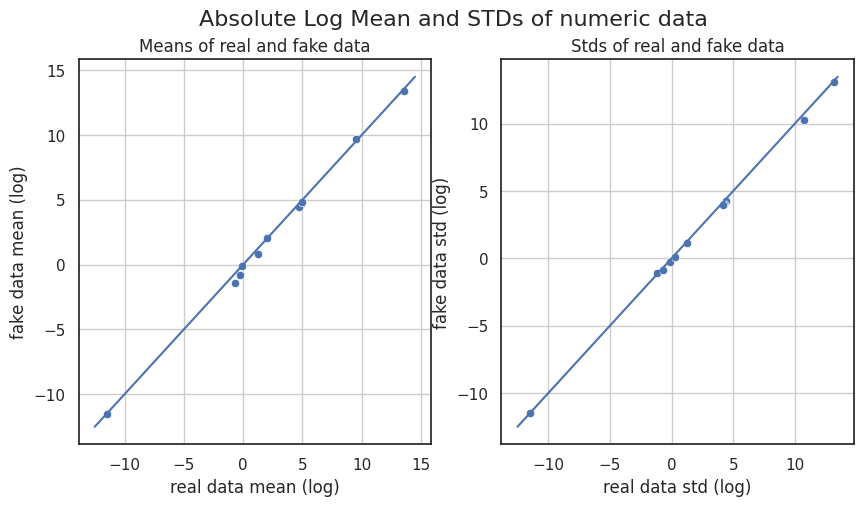

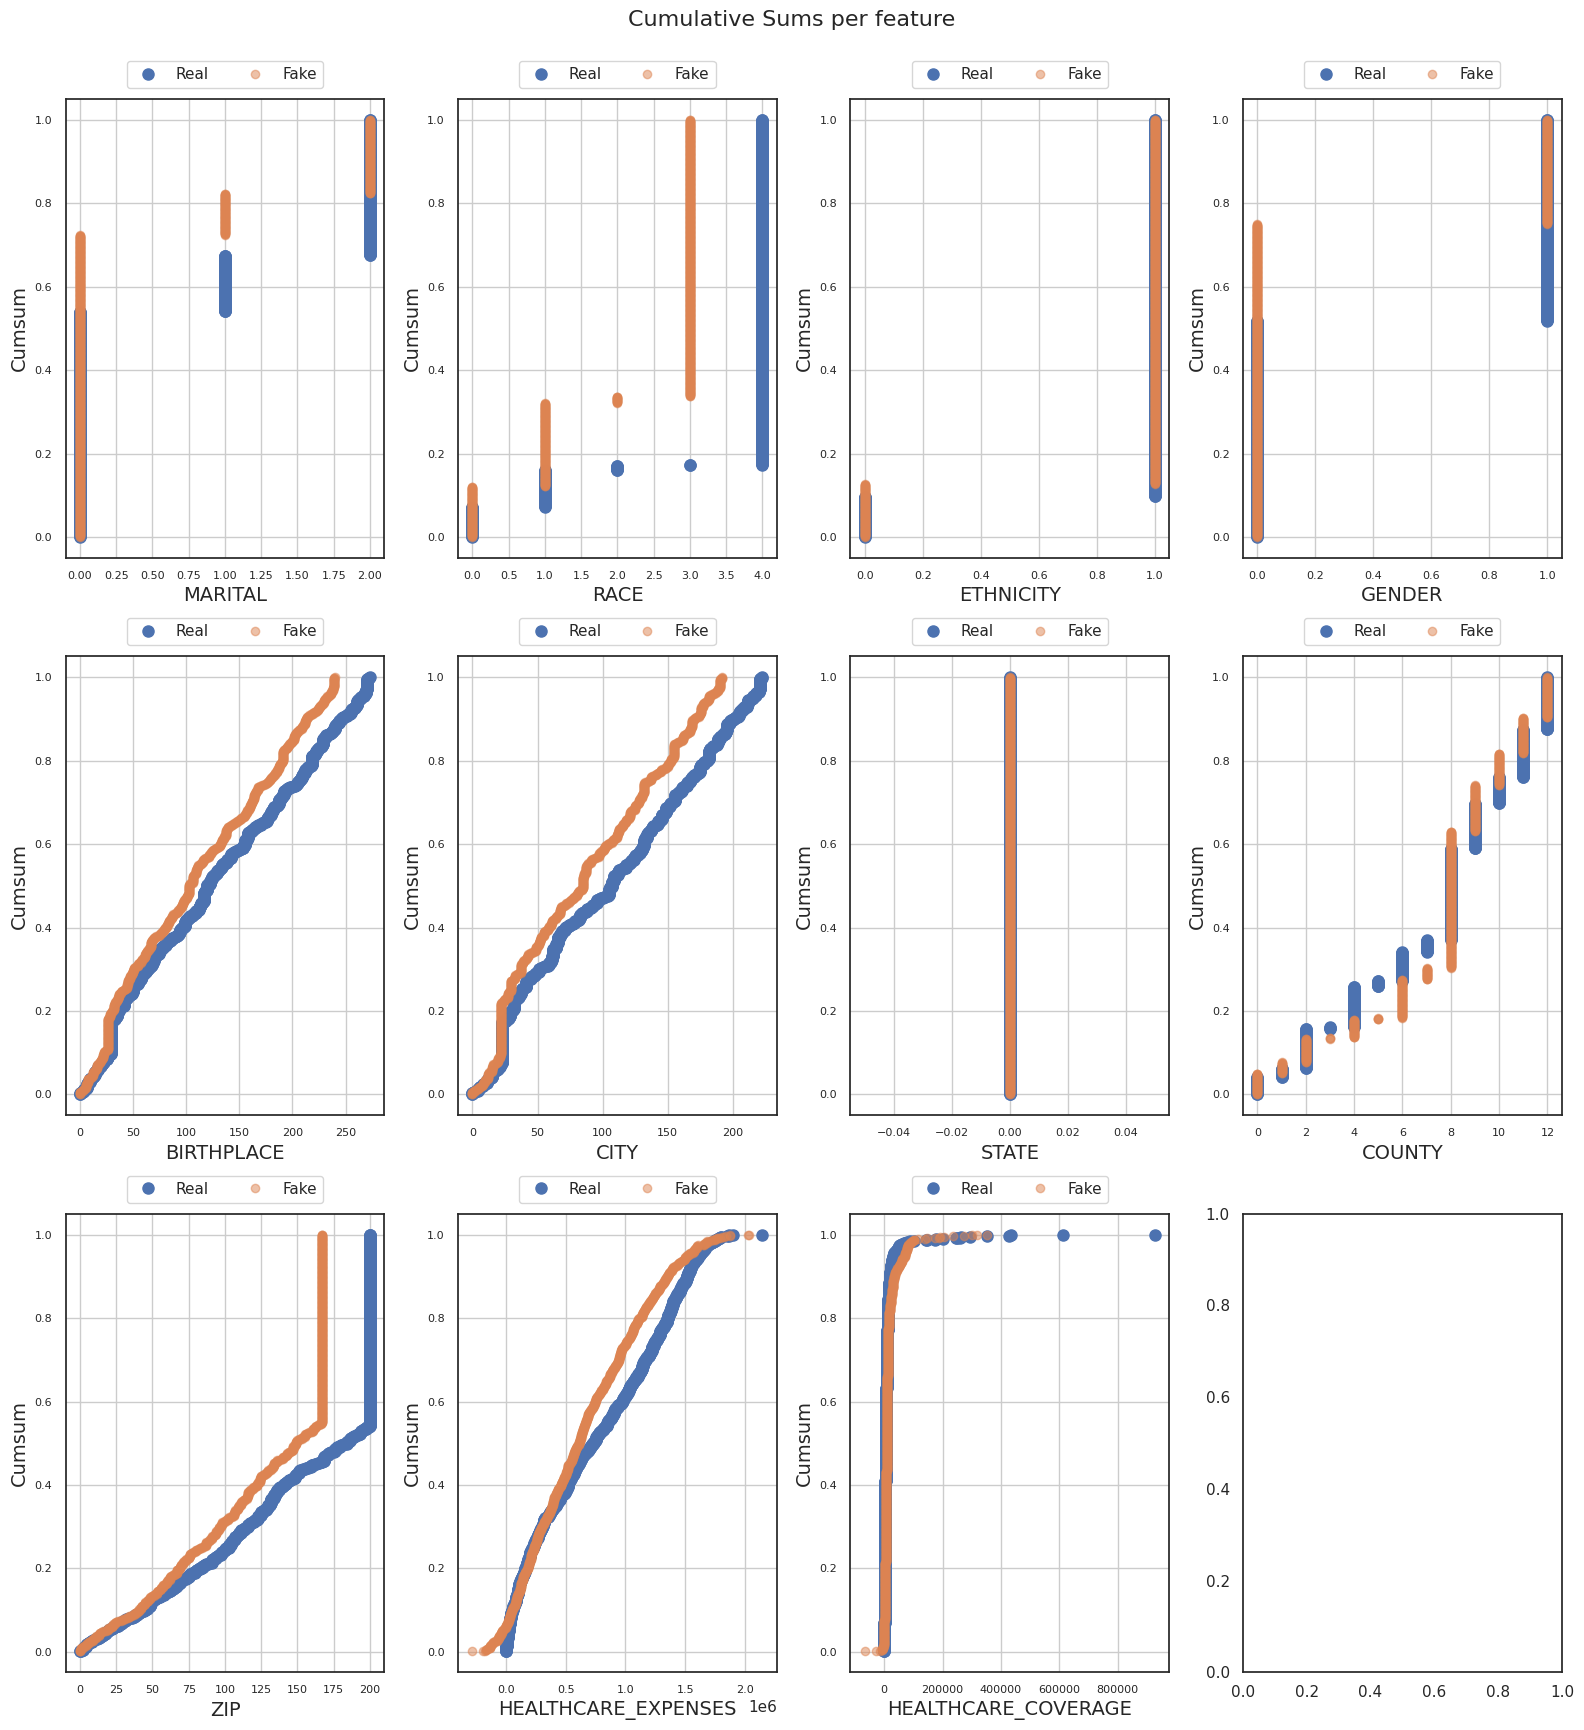

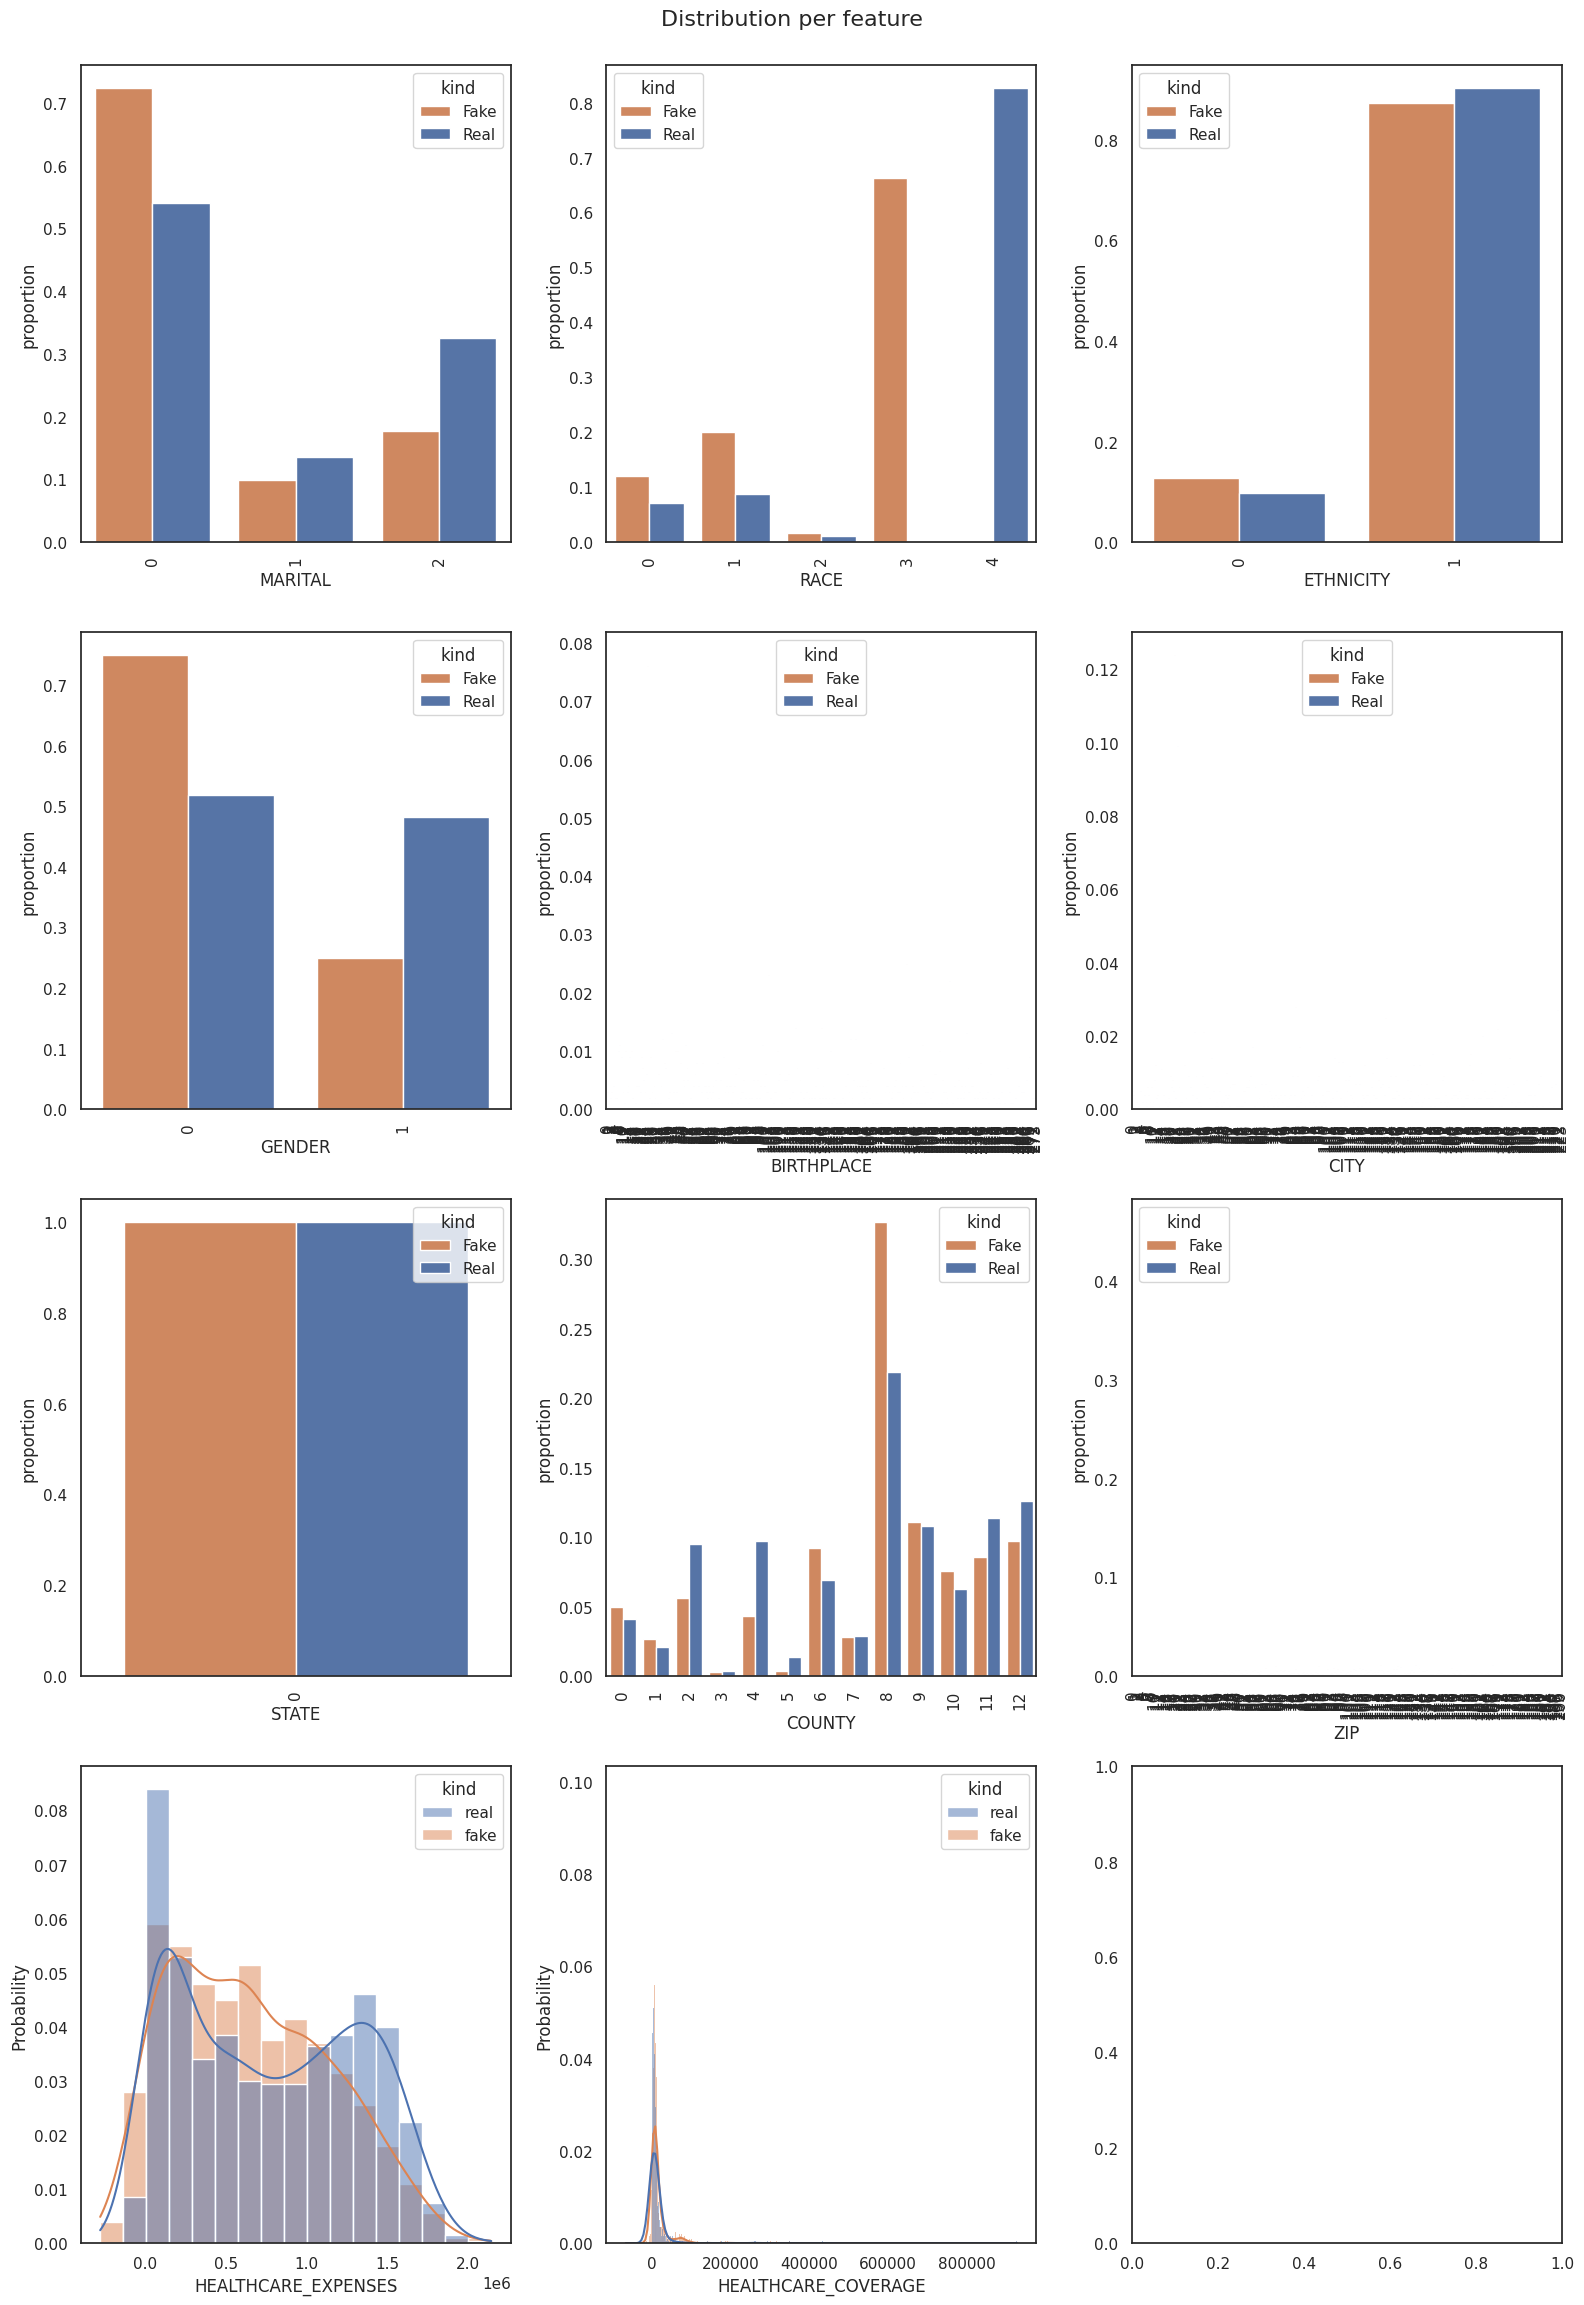

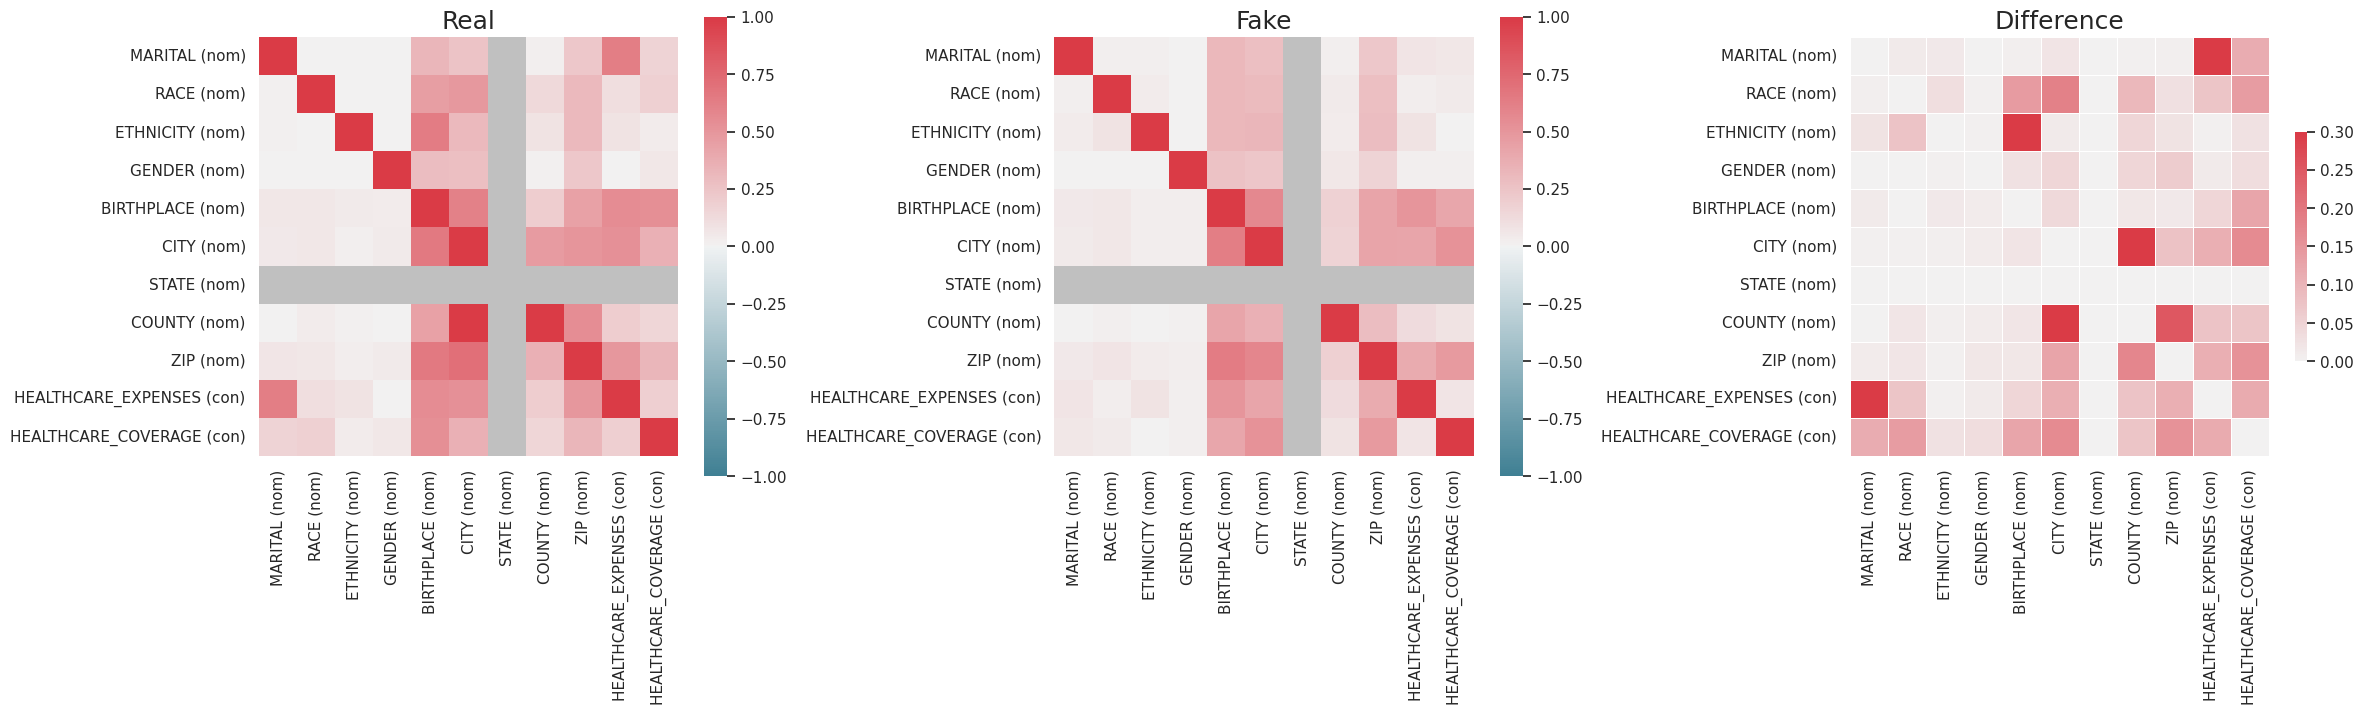

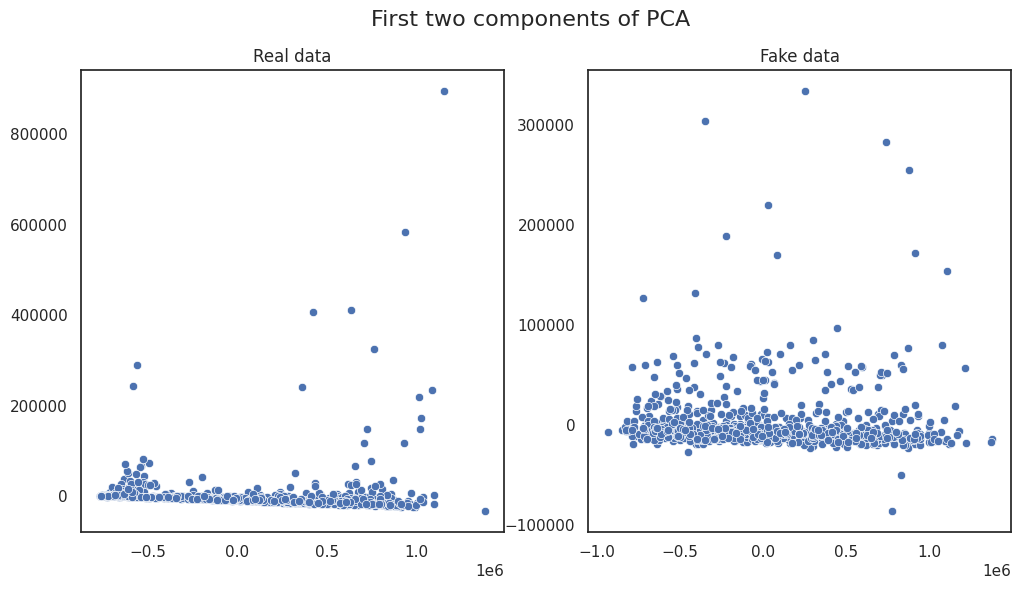

In [ ]:
table_evaluator.visual_evaluation()

## Conclusion

As its apparent from the visualizations, the similarity between the original data and the synthetic data is quite high. The results give a lot of confidence as we took a random dataset and applied the default implementation without any tweaks or any data preprocessing.

The model can be used in various scenarios where data augmentation is required. Its worthwhile to highlight a few caveats:
- In this dataset we just had categorical and continuous variables and the results were quite good.
- It would be useful to try it on datasets with date time values
- Also this model won't be able to handle relational datasets by default. For eg. there's no way of specifiying primary key foreign key constraints.
- Moreover, it cannot handle contraints by default. For eg. a particular state should belong to a single country but there's no way of specifying this constraint. The generated dataset can contain new combinations of (state, country) which is not present in the original dataset.

There's a framework to mitigate some of the above issues. Checkout [SDV](https://sdv.dev/SDV/) if you are interested. I will try to write a post about it in future.